In [1]:
# Names and EID:
# Matthew Pham (map7578)
# Thai
# Jack
# Issay

# Data Cleaning/Exploration, Feature Engineering (v2)

This is the refactored version of our project (`ML-project.ipynb`). **All of our original investigation is kept here**: what we looked at, what we found, and why we made each decision. What changed is *where the code lives* and *how it is validated*:
- cleaning, imputation and feature engineering are scikit-learn transformers in `src/` (each file < 250 lines), so they are re-fit inside every cross-validation fold and can never see validation/test rows;
- models are scored with 5-fold out-of-fold (OOF) CV (`src/cv.py`);
- every idea from v1 was **re-tested the leak-safe way** (section 7), so the conclusions below are backed by numbers.

Libraries: numpy, pandas, scikit-learn (+ matplotlib for plots, as in v1).

## 1. First look
Our first strategy to figure out how to clean the data was to simply look at it in an excel spreadsheet. 
Here are some things we noticed:
* Lots of the categories are non-numerical (breed, climate zone, management system, date, etc.)
* lots of numerical values start with a "'"
* Some negative values don't make sense (rumination time)
* Some blank values
* Feed quantity is present twice

In [2]:
# imports
import sys; sys.path.insert(0, '.')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import load_train, load_test
from src.config import TARGET

# the raw files, exactly as in v1 (cleaning happens later, inside the pipeline)
data = pd.read_csv('cattle_data_train.csv')
test = pd.read_csv('cattle_data_test.csv')
print(data.shape, test.shape)
data.head()

(210000, 36) (40000, 35)


,Cattle_ID,Breed,Climate_Zone,Management_System,Age_Months,Weight_kg,Parity,Lactation_Stage,Days_in_Milk,Feed_Type,...,BVD_Vaccine,Rabies_Vaccine,Previous_Week_Avg_Yield,Body_Condition_Score,Milking_Interval_hrs,Date,Farm_ID,Feed_Quantity_lb,Mastitis,Milk_Yield_L
0,CATTLE_133713,Holstein,Tropical,Intensive,114,544.8,4,Mid,62,Concentrates,...,0,1,6.31,3.0,12,2024-01-15,FARM_0301,36.8235,1,12.192634
1,CATTLE_027003,Holstein,Arid,Mixed,136,298.9,4,Mid,213,Crop_Residues,...,0,0,17.16,4.0,12,2023-10-31,FARM_0219,NaN,0,14.717031
2,CATTLE_122459,Holstein,Tropical,Semi_Intensive,64,336.6,4,Late,16,Hay,...,1,0,4.07,3.5,12,2024-05-20,FARM_0802,16.0965,0,14.006142
3,CATTLE_213419,Jersey,Mediterranean,Intensive,58,370.5,1,Early,339,Crop_Residues,...,0,0,10.23,3.0,24,2024-07-22,FARM_0034,40.7925,0,24.324325
4,CATTLE_106260,Guernsey,Subtropical,Intensive,84,641.5,6,Early,125,Mixed_Feed,...,1,1,20.68,3.0,12,2023-01-03,FARM_0695,33.7365,1,12.023074


## 2. What kind of problem is this?
**Tabular regression** - not classification and not time-series. How we know:
- **Not classification:** `Milk_Yield_L` is continuous (every one of the 210,000 rows has a different value) and `sample_submission.csv` asks for a decimal number per `Cattle_ID`. `Mastitis` is 0/1 but it is an *input* column, not the label.
- **Not time-series:** `Date` covers 2022-01-01..2024-12-30 in *both* train and test, i.e. the test rows are interleaved with training rows (a random split, not 'predict the future'). Every row is a different cow (only 34 repeated IDs), so there is no sequence to forecast. Date only carries a yearly *seasonal* pattern, so we use it as a feature and cross-validate with shuffled KFold instead of a time-ordered split.
- **Grouping not needed:** all 1,000 farms appear in both train and test, so we do not need a grouped (by farm) split.

count    210000.000000
mean         15.589156
std           5.352079
min          -5.700324
25%          11.822207
50%          15.145871
75%          18.884708
max          44.555285
Name: Milk_Yield_L, dtype: float64
unique target values: 210000 of 210000
train dates 2022-01-01 -> 2024-12-30 | test dates 2022-01-01 -> 2024-12-30
repeated Cattle_IDs in train: 34
farms in train / test / both: 1000 1000 1000
Mastitis rate: 0.1


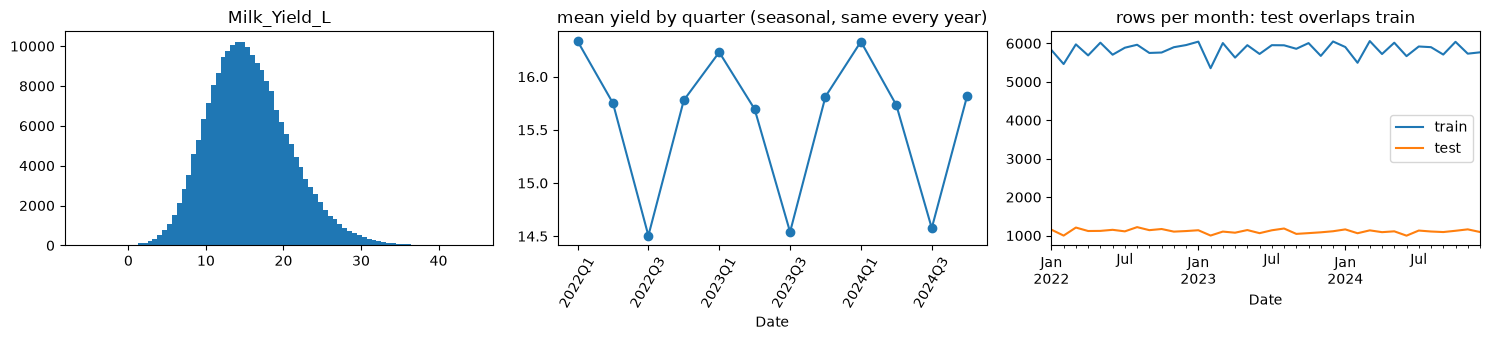

In [3]:
y = data[TARGET]
print(y.describe())
print('unique target values:', y.nunique(), 'of', len(y))
d_tr, d_te = pd.to_datetime(data.Date), pd.to_datetime(test.Date)
print('train dates', d_tr.min().date(), '->', d_tr.max().date(), '| test dates', d_te.min().date(), '->', d_te.max().date())
print('repeated Cattle_IDs in train:', data.Cattle_ID.duplicated().sum())
print('farms in train / test / both:', data.Farm_ID.nunique(), test.Farm_ID.nunique(), len(set(data.Farm_ID) & set(test.Farm_ID)))
print('Mastitis rate:', round(data.Mastitis.mean(), 3))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ax[0].hist(y, bins=80); ax[0].set_title('Milk_Yield_L')
y.groupby(d_tr.dt.to_period('Q').astype(str)).mean().plot(ax=ax[1], marker='o'); ax[1].set_title('mean yield by quarter (seasonal, same every year)')
ax[1].tick_params(axis='x', rotation=60)
d_tr.dt.to_period('M').value_counts().sort_index().plot(ax=ax[2], label='train'); d_te.dt.to_period('M').value_counts().sort_index().plot(ax=ax[2], label='test')
ax[2].set_title('rows per month: test overlaps train'); ax[2].legend(); plt.tight_layout(); plt.show()

## 3. Cleaning exploration (from v1)
Findings from looking at the spreadsheet and the data: leading `'` on some numbers (pandas parses them fine), negative `Rumination_Time_hrs`, blanks, and `Feed_Quantity` in both kg and lb.

In [4]:
# checking which columns have missing values
data.isna().sum()[lambda s: s > 0]

Feed_Quantity_kg    10481
Housing_Score        6279
Feed_Quantity_lb    10481
dtype: int64

In [5]:
# Number of unique values in each column + category check
print(data['Breed'].unique())  # found that some names are wrong for the cows
print(data['Breed'].replace('Holstien', 'Holstein').str.strip().unique())
ratio = data.Feed_Quantity_lb / data.Feed_Quantity_kg
print('Feed_Quantity_lb / Feed_Quantity_kg ranges', ratio.min().round(2), '-', ratio.max().round(2), '| corr', round(data.Feed_Quantity_lb.corr(data.Feed_Quantity_kg), 4), '| NaN in exactly the same rows:', bool((data.Feed_Quantity_lb.isna() == data.Feed_Quantity_kg.isna()).all()))
print('negative Rumination_Time_hrs rows:', (data.Rumination_Time_hrs < 0).sum(), 'of', len(data), '| negative targets:', (y < 0).sum())

<StringArray>
[    'Holstein',       'Jersey',     'Guernsey',  'Brown Swiss',
 ' Brown Swiss',     'Holstien', 'Brown Swiss ']
Length: 7, dtype: str
<StringArray>
['Holstein', 'Jersey', 'Guernsey', 'Brown Swiss']
Length: 4, dtype: str
Feed_Quantity_lb / Feed_Quantity_kg ranges 1.77 - 2.79 | corr 0.9988 | NaN in exactly the same rows: True
negative Rumination_Time_hrs rows: 115627 of 210000 | negative targets: 74


**Decision:** fix the breed spelling/whitespace (`BreedCleaner`); drop `Feed_Quantity_lb`: it is a (noisy) second copy of the kg column - correlation 0.999 and missing in exactly the same rows - so it adds no information. More than half of `Rumination_Time_hrs` is negative, which is impossible for hours (see section 5 for what we did with it).

## 4. Missing values: how should we impute `Housing_Score` and `Feed_Quantity_kg`?
Our reasoning in v1 (kept): we considered how to impute the missing values for housing score and feed amount. One thought was that maybe all the cows from one farm are missing a housing score/feed amount. We found that this is not the case: the max missing from any given farm is 22 for either one. We then explored using the mean housing score or feed amount from a given farm to impute missing values. Intuitively both make sense, but we found that, within farms, housing score varies very little in absolute terms (variance 0.0410) while feed amount varies a lot (15.75). But the variance across the *whole* data set is almost identical for both (0.0410 and 15.755), as were the means, so for **both** columns a farm's average is barely different from the global average.

The cell below re-computes those numbers.

In [6]:
g = data.groupby('Farm_ID')
max_missing = max(g.Housing_Score.apply(lambda s: s.isna().sum()).max(), g.Feed_Quantity_kg.apply(lambda s: s.isna().sum()).max())
print('max missing from any given farm:', max_missing)
print('mean within-farm variance  housing: %.4f  feed: %.3f' % (g.Housing_Score.var().mean(), g.Feed_Quantity_kg.var().mean()))
print('whole-data variance        housing: %.4f  feed: %.3f' % (data.Housing_Score.var(), data.Feed_Quantity_kg.var()))
print('spread of farm means (std) housing: %.4f  feed: %.3f' % (g.Housing_Score.mean().std(), g.Feed_Quantity_kg.mean().std()))
print('missing housing:', data.Housing_Score.isna().sum(), '| missing feed:', data.Feed_Quantity_kg.isna().sum())

max missing from any given farm: 22
mean within-farm variance  housing: 0.0410  feed: 15.749
whole-data variance        housing: 0.0410  feed: 15.755
spread of farm means (std) housing: 0.0145  feed: 0.290
missing housing: 6279 | missing feed: 10481


**What this told us:**
- No farm is missing everything (max 22 missing values for any farm), so farm statistics exist for every farm.
- Farm identity carries almost no information about either column (farm means barely differ from the global mean), so **farm-median imputation is expected to be no better than a global median**. v1 used the farm median for housing anyway (harmless: it falls back to the global median for unseen farms); section 7 tests farm vs global median directly.
- Both columns get a `*_missing` flag, in case missingness itself is informative.
- For feed we also tested KNN and RandomForest imputers (v1) and re-score them in section 7.

## 5. Correlation analysis (from v1)

corr(Rumination_Time_hrs, Previous_Week_Avg_Yield) = 1.0


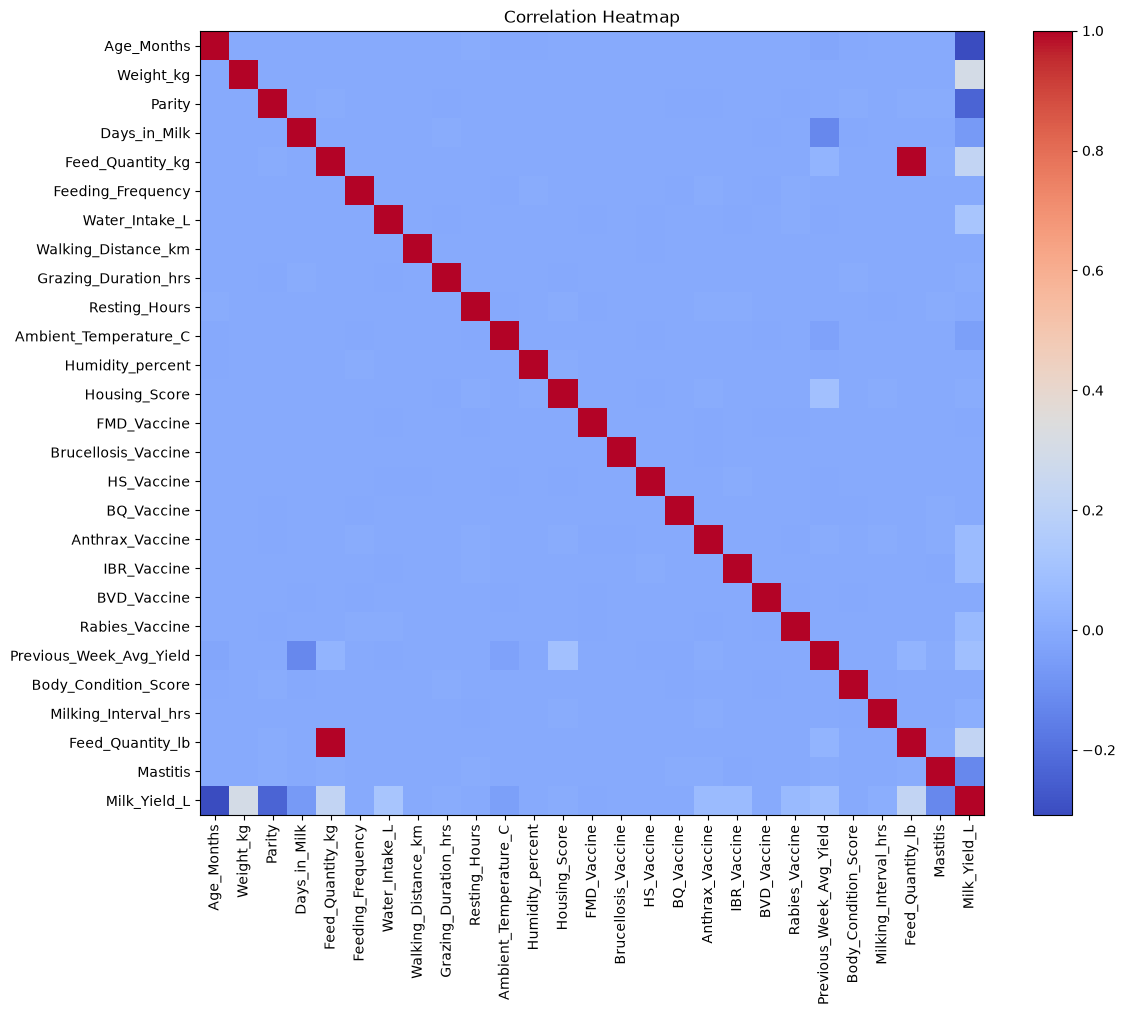

Age_Months                -0.309
Weight_kg                  0.300
Parity                    -0.237
Feed_Quantity_lb           0.224
Feed_Quantity_kg           0.223
Water_Intake_L             0.125
Mastitis                  -0.123
Previous_Week_Avg_Yield    0.090
IBR_Vaccine                0.072
Anthrax_Vaccine            0.070
Rabies_Vaccine             0.069
Days_in_Milk              -0.063
Name: Milk_Yield_L, dtype: float64
most correlated pairs of INPUT features:
Feed_Quantity_kg  Feed_Quantity_lb           0.9988
Days_in_Milk      Previous_Week_Avg_Yield    0.1222
Housing_Score     Previous_Week_Avg_Yield    0.0981
dtype: float64
...and the 4th largest is only 0.0407


In [7]:
# `Rumination_Time_hrs` vs `Previous_Week_Avg_Yield`
print('corr(Rumination_Time_hrs, Previous_Week_Avg_Yield) =', round(data.Rumination_Time_hrs.corr(data.Previous_Week_Avg_Yield), 6))
numeric_cols = data.drop(columns=['Rumination_Time_hrs']).select_dtypes(include='number')
corr_matrix = numeric_cols.corr()

plt.figure(figsize=(12, 10))
plt.imshow(corr_matrix, cmap='coolwarm', interpolation='nearest')
plt.colorbar()
plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=90)
plt.yticks(range(len(corr_matrix.columns)), corr_matrix.columns)
plt.title('Correlation Heatmap'); plt.tight_layout(); plt.show()

print(corr_matrix[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).head(12))
inputs = corr_matrix.drop(index=TARGET, columns=TARGET)
pairs = inputs.where(np.triu(np.ones(inputs.shape, dtype=bool), 1)).stack().abs().sort_values(ascending=False)
print('most correlated pairs of INPUT features:'); print(pairs.head(3).round(4)); print('...and the 4th largest is only', round(pairs.iloc[3], 4))

**What this told us**
- `Rumination_Time_hrs` is a **1-to-1 copy** of `Previous_Week_Avg_Yield` (correlation 1.0), so we drop one and lose no information.
- The strongest linear relationships with the target are Age (-0.31), Weight (+0.30), Parity (-0.24), Feed quantity (+0.22), Water intake (+0.13), Mastitis (-0.12), Previous-week yield (+0.09) and Days in milk (-0.06).
- Apart from the duplicate feed columns, the input features are almost uncorrelated with *each other*, so there is nothing to impute `Feed_Quantity_kg`/`Housing_Score` from - consistent with the imputation findings above - and it hints that interaction/polynomial terms may not add much (tested in section 7).
- `Lactation_Stage` (from our online research) is defined directly from `Days_in_Milk`, so it adds no information -> dropped. We also drop `Cattle_ID`, and `Farm_ID` after it has been used for imputation, because IDs can only throw the model off.

## 6. Record of the v1 pipeline (kept for reference, not executed)
These are the original cells with the results we recorded at the time. They were fit on the whole training set before cross-validation, which is why we re-implemented them as in-fold transformers (next table) and re-tested them in section 7.

### 6a. Imputation (farm-median housing + KNN feed), month one-hot, drop columns
```python
from sklearn.impute import KNNImputer

# Since housing score varies little within farms (VAR: 0.041 within farms vs 0.041 overall),
# we can use farm-level imputation for Housing_Score.
# For Feed_Quantity_kg, high variance within farms (VAR: 15.75) suggests KNN imputation
# based on similar cows (age, weight, parity) would be better.

data_imputed = data.copy()

# Track which values were imputed
data_imputed["housing_imputed"] = data_imputed["Housing_Score"].isna().astype(int)
data_imputed["feed_imputed"] = data_imputed["Feed_Quantity_kg"].isna().astype(int)

# Calculate farm-level medians
farm_housing_median = data_imputed.groupby('Farm_ID')['Housing_Score'].transform('median')

# Fill missing values with farm median
data_imputed['Housing_Score'] = data_imputed['Housing_Score'].fillna(farm_housing_median)

# If any still missing (entire farm missing), use global median
global_housing_median = data_imputed['Housing_Score'].median()
data_imputed['Housing_Score'] = data_imputed['Housing_Score'].fillna(global_housing_median)

# Select features that predict feed quantity
knn_features = ['Age_Months', 'Weight_kg', 'Parity', 'Days_in_Milk', 
                'Water_Intake_L', 'Body_Condition_Score', 'Feed_Quantity_kg']

# Create temporary dataframe with only these features
temp_knn_data = data_imputed[knn_features].copy()

# KNN Imputer: use 5 nearest neighbors
knn_imputer = KNNImputer(n_neighbors=5, weights='distance')
temp_knn_imputed = knn_imputer.fit_transform(temp_knn_data)

# Replace only the Feed_Quantity_kg column
data_imputed['Feed_Quantity_kg'] = temp_knn_imputed[:, -1]

data_imputed = data_imputed.drop(columns=['Feed_Quantity_lb'])

print(f"Total missing values remaining: {data_imputed.isna().sum().sum()}")
print(f"housing_imputed: {data_imputed['housing_imputed'].sum()} rows")
print(f"feed_imputed: {data_imputed['feed_imputed'].sum()} rows")
```

Recorded output: `Total missing values remaining: 0`, `housing_imputed: 6279 rows`, `feed_imputed: 10481 rows`.

```python
# according to online, the lactation stages should be defined directly from the days_in_milk.
# Therefore, we are not adding any new information with the Lactation_Stage column.
# Therefore, we will remove it. 

data_imputed = data_imputed.drop(columns=['Lactation_Stage'])
data_imputed = data_imputed.drop(columns=['Cattle_ID'])

# We also drop the ID columns as those can only throw off the model. 
data_imputed = data_imputed.drop(columns=['Farm_ID'])


# We one hot encode the dates by month. Maybe one season/month will produce more milk than another. 
data_imputed['Date'] = pd.to_datetime(data_imputed['Date'])          # convert to datetime
data_imputed['Month'] = data_imputed['Date'].dt.month                # 1–12 integers (or .dt.month_name())
data_imputed = data_imputed.drop(columns=['Date'])

# one-hot encode the month
data_imputed = pd.get_dummies(data_imputed, columns=['Month'], prefix='month', drop_first=False, dtype=int)
```

### 6b. Outlier detection (4 detectors, >= 2 votes)
We scaled the data and ran EllipticEnvelope, IsolationForest, LocalOutlierFactor and OneClassSVM (contamination 1%); rows flagged by at least 2 were removed. Recorded result: **1,974 rows removed** (208,026 left). EllipticEnvelope warned that the covariance matrix is not full rank (one-hot columns).

```python
# Here we handle outliers that might adversely affect how our model predicts
# the test data. 

from sklearn.preprocessing import StandardScaler
from sklearn.covariance import EllipticEnvelope
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM



# scale data
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data_OHE)

# elliptic envelope outlier prediction
ee = EllipticEnvelope(contamination=0.01, random_state=42)
ee_labels = ee.fit_predict(data_scaled)   # +1 = normal, -1 = outlier

# isolation forest outlier prediction
iso = IsolationForest(contamination=0.01, random_state=42)
iso_labels = iso.fit_predict(data_scaled)

# local outlier factor prediction

lof = LocalOutlierFactor(contamination=0.01)
lof_labels = lof.fit_predict(data_scaled)

#SVM outlier prediciton
ocsvm = OneClassSVM(nu=0.01, kernel='rbf', gamma='scale')
ocsvm_labels = ocsvm.fit_predict(data_scaled)



#create table of outliers by function

df_outliers = pd.DataFrame({
    "EllipticEnvelope": ee_labels,
    "IsolationForest": iso_labels,
    "LOF": lof_labels,
    "OneClassSVM": ocsvm_labels
})

# Convert +1/-1 => more intuitive
df_outliers = df_outliers.replace({1: "normal", -1: "outlier"})


outliers_ee = df_outliers[df_outliers["EllipticEnvelope"] == "outlier"].index
outliers_iso = df_outliers[df_outliers["IsolationForest"] == "outlier"].index
outliers_lof = df_outliers[df_outliers["LOF"] == "outlier"].index
outliers_svm = df_outliers[df_outliers["OneClassSVM"] == "outlier"].index


df_outliers["votes"] = (
    (df_outliers == "outlier").sum(axis=1)
)

consensus_outliers = df_outliers[df_outliers["votes"] >= 2].index
```

### 6c. Applying the same transformations to the test set (v1 had to hand-copy every step)
```python
# Apply ALL the same transformations to test set
test_clean = test.copy()

# breed names
test_clean["Breed"] = test_clean["Breed"].replace("Holstien", "Holstein")
test_clean["Breed"] = test_clean["Breed"].str.strip()

# remove Rumination_Time_hrs
if 'Rumination_Time_hrs' in test_clean.columns:
    test_clean = test_clean.drop(columns=['Rumination_Time_hrs'])

# impute missing values with the same medians from training data
test_clean["housing_missing"] = test_clean["Housing_Score"].isna().astype(int)
test_clean["feed_missing"] = test_clean["Feed_Quantity_kg"].isna().astype(int)
test_clean['Housing_Score'] = test_clean['Housing_Score'].fillna(test_clean['Farm_ID'].map(farm_housing_median))
test_clean['Housing_Score'] = test_clean['Housing_Score'].fillna(global_housing_median)
for col in knn_features:
    if col not in test_clean.columns:
        test_clean[col] = 0
temp_knn_test = test_clean[knn_features].copy()
temp_knn_test_imputed = knn_imputer.transform(temp_knn_test)
test_clean['Feed_Quantity_kg'] = temp_knn_test_imputed[:, -1]

# drop columns
cols_to_drop = ['Feed_Quantity_lb', 'Lactation_Stage', 'Cattle_ID', 'Farm_ID']
test_clean = test_clean.drop(columns=[c for c in cols_to_drop if c in test_clean.columns])

# date to month
test_clean['Date'] = pd.to_datetime(test_clean['Date'])
test_clean['Month'] = test_clean['Date'].dt.month
test_clean = test_clean.drop(columns=['Date'])

# one hot encode data
test_clean = pd.get_dummies(test_clean, columns=['Month'], prefix='month', drop_first=False, dtype=int)
test_clean = pd.get_dummies(test_clean, columns=["Breed", "Management_System", "Feed_Type", "Climate_Zone"], drop_first=False, dtype=int)

# same columns as training data
train_cols = set(data_OHE.columns) - {'Milk_Yield_L'}
test_cols = set(test_clean.columns) - {'Milk_Yield_L'}

# add missing columns to test with zeros
for col in train_cols - test_cols:
    test_clean[col] = 0

# reorder test columns to match training
test_clean = test_clean[[col for col in data_OHE.columns if col != 'Milk_Yield_L' and col in test_clean.columns]]

print(f"Training shape: {data_OHE.shape}")
print(f"Test shape: {test_clean.shape}")
print(f"Test has Milk_Yield_L: {'Milk_Yield_L' in test_clean.columns}")
```

Recorded: training shape (210000, 63), test shape (40000, 62). *In v2 this whole cell disappears: `pipeline.predict(X_test)` applies every step automatically.*

### 6d. Feature-engineering variants
**Biologically motivated features** (DIM stages from Days_in_Milk because the given stage column did not match our research; feed per kg body weight; water-to-feed; age x parity; temperature-humidity heat stress):
```python
# Add biologically motivated features that could improve predictions

data_engineered = data_OHE.copy()
test_engineered = test_clean.copy()

def add_features(df):
    df = df.copy()
    
    # Days in Milk stages, the data given doesn't seem accurate to our research
    # Therefore, we define them directly from Days_in_Milk
    if 'Days_in_Milk' in df.columns:
        df['DIM_early'] = (df['Days_in_Milk'] <= 100).astype(int)
        df['DIM_mid'] = ((df['Days_in_Milk'] > 100) & (df['Days_in_Milk'] <= 200)).astype(int)
        df['DIM_late'] = (df['Days_in_Milk'] > 200).astype(int)
        df['DIM_squared'] = df['Days_in_Milk'] ** 2
    
    # Feed efficiency
    if 'Feed_Quantity_kg' in df.columns and 'Weight_kg' in df.columns:
        df['Feed_per_kg_bodyweight'] = df['Feed_Quantity_kg'] / (df['Weight_kg'] + 1e-6)
    
    # Water-to-feed ratio
    if 'Water_Intake_L' in df.columns and 'Feed_Quantity_kg' in df.columns:
        df['Water_to_Feed_ratio'] = df['Water_Intake_L'] / (df['Feed_Quantity_kg'] + 1e-6)
    
    # Age-Parity interaction (older cows with more births = may have more wear and tear)
    if 'Age_Months' in df.columns and 'Parity' in df.columns:
        df['Age_Parity_product'] = df['Age_Months'] * df['Parity']
    
    # Temperature Humidity Index (THI) - heat stress metric
    if 'Ambient_Temperature_C' in df.columns and 'Humidity_percent' in df.columns:
        df['THI_product'] = df['Ambient_Temperature_C'] * (df['Humidity_percent'] / 100)
        df['Heat_stress_flag'] = ((df['Ambient_Temperature_C'] > 25) & 
                                  (df['Humidity_percent'] > 60)).astype(int)
    
    return df

data_engineered = add_features(data_engineered)
test_engineered = add_features(test_engineered)

# Align test columns with training
train_cols = set(data_engineered.columns) - {'Milk_Yield_L'}
test_cols = set(test_engineered.columns)
for col in train_cols - test_cols:
    test_engineered[col] = 0
test_engineered = test_engineered[[col for col in data_engineered.columns if col != 'Milk_Yield_L' and col in test_engineered.columns]]
```

**RandomForest imputer** for feed (alternative to KNN):
```python
# Instead of KNN, use Random Forest to predict missing Feed_Quantity_kg
# This can capture non-linear relationships better

from sklearn.ensemble import RandomForestRegressor

data_rf_impute = data.copy()

# Track missing
data_rf_impute["housing_imputed"] = data_rf_impute["Housing_Score"].isna().astype(int)
data_rf_impute["feed_imputed"] = data_rf_impute["Feed_Quantity_kg"].isna().astype(int)

# For housing use same farm-level median approach
farm_housing_median_rf = data_rf_impute.groupby('Farm_ID')['Housing_Score'].transform('median')
data_rf_impute['Housing_Score'] = data_rf_impute['Housing_Score'].fillna(farm_housing_median_rf)
global_housing_median_rf = data_rf_impute['Housing_Score'].median()
data_rf_impute['Housing_Score'] = data_rf_impute['Housing_Score'].fillna(global_housing_median_rf)

# For feed use Random Forest imputation
feed_features = ['Age_Months', 'Weight_kg', 'Parity', 'Days_in_Milk', 
                 'Water_Intake_L', 'Body_Condition_Score']

has_feed = data_rf_impute[data_rf_impute['Feed_Quantity_kg'].notna()]
missing_feed = data_rf_impute[data_rf_impute['Feed_Quantity_kg'].isna()]

if len(missing_feed) > 0:
    rf_imputer = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    rf_imputer.fit(has_feed[feed_features], has_feed['Feed_Quantity_kg'])
    
    predicted_feed = rf_imputer.predict(missing_feed[feed_features])
    data_rf_impute.loc[data_rf_impute['Feed_Quantity_kg'].isna(), 'Feed_Quantity_kg'] = predicted_feed

data_rf_impute = data_rf_impute.drop(columns=['Feed_Quantity_lb'])
```

**Percentile capping** instead of removing outliers:
```python
# Instead of removing outliers, cap extreme values at percentiles
# This preserves data while reducing impact of outliers

data_capped = data_OHE.copy()

def cap_outliers(df, columns, lower_percentile=1, upper_percentile=99):
    df = df.copy()
        
    for col in columns:
        if col in df.columns:
            lower_bound = df[col].quantile(lower_percentile / 100)
            upper_bound = df[col].quantile(upper_percentile / 100)
            
            original_min = df[col].min()
            original_max = df[col].max()
            
            df[col] = df[col].clip(lower=lower_bound, upper=upper_bound)
            
            capped_count = ((df[col] == lower_bound) | (df[col] == upper_bound)).sum()
    
    return df

# Apply to continuous variables that might have extreme values
continuous_cols = ['Age_Months', 'Weight_kg', 'Days_in_Milk', 'Feed_Quantity_kg',
                   'Water_Intake_L', 'Walking_Distance_km', 'Grazing_Duration_hrs',
                   'Resting_Hours', 'Ambient_Temperature_C', 'Humidity_percent',
                   'Previous_Week_Avg_Yield', 'Body_Condition_Score', 'Milking_Interval_hrs']

data_capped = cap_outliers(data_capped, continuous_cols)
```

**Interactions:**
```python
# Create interaction terms between highly correlated features
# Based on correlation matrix analysis

data_interactions = data_OHE.copy()

# Top interactions based on domain knowledge and correlations
if 'Feed_Quantity_kg' in data_interactions.columns and 'Weight_kg' in data_interactions.columns:
    data_interactions['Feed_Weight_interaction'] = data_interactions['Feed_Quantity_kg'] * data_interactions['Weight_kg']

if 'Ambient_Temperature_C' in data_interactions.columns and 'Humidity_percent' in data_interactions.columns:
    data_interactions['Temp_Humidity_interaction'] = data_interactions['Ambient_Temperature_C'] * data_interactions['Humidity_percent']

if 'Age_Months' in data_interactions.columns and 'Parity' in data_interactions.columns:
    data_interactions['Age_Parity_interaction'] = data_interactions['Age_Months'] * data_interactions['Parity']

if 'Days_in_Milk' in data_interactions.columns and 'Previous_Week_Avg_Yield' in data_interactions.columns:
    data_interactions['DIM_PrevYield_interaction'] = data_interactions['Days_in_Milk'] * data_interactions['Previous_Week_Avg_Yield']
```

**Log transforms:**
```python
# Some features might be highly skewed - log transform can help
import numpy as np

data_log = data_OHE.copy()

def log_transform_skewed(df, threshold=0.5):
    df = df.copy()
    
    continuous_features = df.select_dtypes(include=[np.number]).columns
    
    for col in continuous_features:
        if col != 'Milk_Yield_L':
            skewness = df[col].skew()
            
            if abs(skewness) > threshold:
                df[f'{col}_log'] = np.log1p(df[col])    
    return df

data_log = log_transform_skewed(data_log)
```

**Polynomials** (Age, Weight, DIM; from correlations Age -0.309, Weight +0.300, DIM -0.062):
```python
# Add polynomial features for top predictors (Age, Weight, Days_in_Milk)
# These have non-linear relationships with milk yield

data_poly = data_OHE.copy()

# Based on correlation: Age_Months (-0.309), Weight_kg (+0.300), Days_in_Milk (-0.062)
if 'Age_Months' in data_poly.columns:
    data_poly['Age_squared'] = data_poly['Age_Months'] ** 2
    data_poly['Age_cubed'] = data_poly['Age_Months'] ** 3

if 'Weight_kg' in data_poly.columns:
    data_poly['Weight_squared'] = data_poly['Weight_kg'] ** 2

if 'Days_in_Milk' in data_poly.columns:
    data_poly['DIM_squared'] = data_poly['Days_in_Milk'] ** 2
    data_poly['DIM_cubed'] = data_poly['Days_in_Milk'] ** 3
```

**Comparison harness** (RandomForest 50 trees, 3-fold):
```python
# Quick comparison of different preprocessing approaches
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score
import numpy as np

approaches = {
    'Baseline (current)': data_OHE,
    'With Feature Engineering': data_engineered,
    'With Capping': data_capped,
    'With Interactions': data_interactions,
    'With Log Transforms': data_log,
    'With Polynomials': data_poly,
}

results = {}

for name, dataset in approaches.items():
    clean_dataset = dataset.drop(index=consensus_outliers).reset_index(drop=True)
    
    X = clean_dataset.drop(columns=['Milk_Yield_L'])
    y = clean_dataset['Milk_Yield_L']
    
    rf = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
    
    cv_scores = cross_val_score(rf, X, y, cv=3, scoring='neg_mean_squared_error', n_jobs=-1)
    rmse = np.sqrt(-cv_scores.mean())
    
    results[name] = rmse
    print(f"{name:30s} RMSE: {rmse:.4f}")

# Find best approach
best_approach = min(results, key=results.get)
print(f"Best approach: {best_approach}")
print(f"RMSE improvement: {results['Baseline (current)'] - results[best_approach]:.4f}")
```

(No output was saved for this cell in v1.)

### 6e. Modeling attempts
**Kernel ridge regression** - did NOT work: it needs an n x n kernel matrix, impossible for 210k rows (especially inside a grid search with k-fold CV); it crashed our machines, so we pivoted to a less memory-intensive model.

```python
# DO NOT RUN!!!!
# We tried out a kernel ridge regression. This did NOT work, as we realized that 
# Kernel Ridge regression needs n^2 memory space to run, which for a large 
# training set is impossible, especially if multiplied via gridsearch for k-fold
# cross validation. The below code crashed our machines.
# We now pivot, opting for a less memory-intensive and more realistic option. 

# from sklearn.kernel_ridge import KernelRidge
# from sklearn.model_selection import GridSearchCV
# from sklearn.metrics import make_scorer, mean_squared_error
# import numpy as np
# from sklearn.pipeline import Pipeline
# from sklearn.preprocessing import StandardScaler

# # Custom RMSE scorer (scikit-learn minimizes negative scores for CV)
# rmse = make_scorer(lambda y_true, y_pred: 
#                    np.sqrt(mean_squared_error(y_true, y_pred)),
#                    greater_is_better=False)

# # Kernel Ridge with sigmoid kernel
# krr = KernelRidge(kernel='sigmoid')

# pipe = Pipeline([
#     ("scaler", StandardScaler()),
#     ("krr", KernelRidge(kernel="rbf"))
# ])

# param_grid = {
#     "krr__alpha": np.logspace(-2, 2, 5),
#     "krr__gamma": np.logspace(-2, 2, 5)
# }

# grid = GridSearchCV(pipe, param_grid, cv=5, scoring=rmse)

# # Fit the grid search
# grid.fit(X_train, y_train)

# print("Best alpha:", grid.best_params_['krr__alpha'])
# print("Best gamma:", grid.best_params_['krr__gamma'])
# print("Best CV RMSE:", -grid.best_score_)  # negate because scorer is negative
```

**MLP (sklearn `MLPRegressor`)** with grid search over architecture, alpha, learning rate and momentum (81 candidates x 5 folds = 405 fits), on the one-hot data with outliers removed:
```python
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, cross_val_score
import numpy as np

# Can use these datasets from previous cells, just uncomment to use
# Default, just the one hot encoded data
dataset_name = "Baseline"
data_to_use = data_OHE
test_to_use = test_clean

# With Feature Engineering
# dataset_name = "Feature Engineering"
# data_to_use = data_engineered
# test_to_use = test_engineered

# With Capping (extreme values capped at 1st/99th percentile, should test more)
# dataset_name = "Capping"
# data_to_use = data_capped
# test_to_use = test_clean

# With Interactions with each other (Age*Parity, Temp*Humidity...)
# dataset_name = "Interactions"
# data_to_use = data_interactions
# test_to_use = test_clean

# With Log Transforms (skewed features log transformed)
# dataset_name = "Log Transforms"
# data_to_use = data_log
# test_to_use = test_clean

# With Polynomials (Age **2, Age **3, Weight **2, DIM **2, DIM **3)
# dataset_name = "Polynomials"
# data_to_use = data_poly
# test_to_use = test_clean

# remove consensus outliers from training data and prep data
data_cleaned = data_OHE.drop(index=consensus_outliers).reset_index(drop=True)
print(f"Removed {len(consensus_outliers)} outliers")
print(f"Training samples after cleaning: {data_cleaned.shape[0]:,}")

X_train = data_cleaned.drop(columns=['Milk_Yield_L'])
y_train = data_cleaned['Milk_Yield_L']

# Match test set columns
X_test = test_to_use.copy()
train_cols = set(X_train.columns)
test_cols = set(X_test.columns)

for col in train_cols - test_cols:
    X_test[col] = 0

X_test = X_test[[col for col in X_train.columns if col in X_test.columns]]

scaler = StandardScaler()
mlp = MLPRegressor(max_iter=1000, random_state=16, early_stopping=True, verbose=False)

pipeline = Pipeline([
    ('scaler', scaler),
    ('mlp', mlp)
])

# params
param_grid = {
    'mlp__hidden_layer_sizes': [(10, 20), (10, 10), (10, 20, 10)],
    'mlp__activation': ['logistic'],
    'mlp__alpha': [0.005, 0.01, 0.05],
    'mlp__solver': ['sgd'],
    'mlp__learning_rate_init': [0.005, 0.01, 0.015] ,
    'mlp__momentum': [0.9, 0.925, 0.95]
}

print("\nRunning grid search with 5-fold cross-validation...")
grid_search = GridSearchCV(pipeline, param_grid, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train)

# cross-validation results
best_rmse_cv = np.sqrt(-grid_search.best_score_)
print(f"Best Parameters: {grid_search.best_params_}")
print(f"Accuracy on training data:")
print(f"RMSE: {best_rmse_cv:.4f}")
print(f"Mean Error: +/-{best_rmse_cv/y_train.mean()*100:.2f}% of average milk yield")

print("\nGenerating test set predictions...")
y_test_pred = grid_search.best_estimator_.predict(X_test)

test_original = pd.read_csv('cattle_data_test.csv')
submission = pd.DataFrame({
    'Cattle_ID': test_original['Cattle_ID'],
    'Milk_Yield_L': y_test_pred
})

submission.to_csv('submission.csv', index=False)

print("Saved predictions to submission.csv")
print(f"\nTest predictions stats:")
print(f"Mean: {y_test_pred.mean():.2f}")
print(f"Min:  {y_test_pred.min():.2f}")
print(f"Max:  {y_test_pred.max():.2f}")
```

Recorded output:
```
Removed 1974 outliers
Training samples after cleaning: 208,026
Best Parameters: {'mlp__activation': 'logistic', 'mlp__alpha': 0.05, 'mlp__hidden_layer_sizes': (10, 10), 'mlp__learning_rate_init': 0.005, 'mlp__momentum': 0.925, 'mlp__solver': 'sgd'}
RMSE: 4.1459
Mean Error: +/-26.60% of average milk yield
Test predictions: mean 15.64, min 7.30, max 25.46
```

### 6f. Leakage audit: what changed from v1 to v2
| v1 step | Problem | v2 replacement |
|---|---|---|
| Outlier detectors fit on the whole training set (and on the target) before CV, rows dropped | validation rows influence which training rows survive; cannot be applied to test rows | in-fold winsorizing (`Winsorizer`); the correctly-done row trimming is re-tested in section 7 |
| Percentile caps computed on all training data | quantiles contain validation info | `Winsorizer` learns quantiles from the training fold only |
| Farm-median housing and global medians computed on all training data | same | `FarmMedianImputer.fit` on the training fold; unseen farms fall back to the global median |
| KNNImputer / RF imputer fit on all data | same | `ModelFeedImputer` (section 7), or global median |
| StandardScaler fit on all data | same | scaler lives inside the model pipeline |
| One-hot via `get_dummies` on train and test separately + manual column alignment | train/test columns can silently differ | `OneHotEncoder(handle_unknown='ignore')` fit on the training fold |
| Test transformations hand-copied cell by cell | easy to drift out of sync | one `Pipeline.predict` |

## 7. Leak-safe re-test of every v1 idea
Each row below is the final v2 pipeline with **one** change (a v1 idea swapped in), scored with the same 5-fold OOF CV and the same tuned HistGradientBoosting model. Code: `src/experiments.py` (`python -m src.experiments` re-creates `reports/experiments.csv`, about 15 minutes on 20 cores). Differences smaller than the fold-to-fold std (~0.013) are noise.

In [8]:
import os
from src.experiments import variants
from src.cv import run_cv

RERUN = False   # True re-runs everything (slow); False reads the saved results from reports/experiments.csv
if RERUN or not os.path.exists('reports/experiments.csv'):
    X, y_, _ = load_train(); X_test, _ = load_test(); rows = []
    for name, pipe in variants().items():
        r = run_cv(pipe, X, y_, X_test)
        rows.append({'variant': name, 'oof_rmse': r['rmse'], 'fold_std': np.std(r['fold_rmse']), 'secs': r['secs']})
    pd.DataFrame(rows).to_csv('reports/experiments.csv', index=False)
res = pd.read_csv('reports/experiments.csv')
ref = res.loc[res.variant.str.startswith('v2 final'), 'oof_rmse'].iloc[0]
res['delta_vs_final'] = res.oof_rmse - ref
res.sort_values('oof_rmse').reset_index(drop=True).round(4)

,variant,oof_rmse,fold_std,secs,delta_vs_final
0,no domain features,4.1433,0.0130,17.5540,-0.0000
1,no winsorizing,4.1433,0.0131,17.8361,-0.0000
2,v2 final (reference),4.1433,0.0132,17.7215,0.0000
3,+ log of skewed (v1),4.1433,0.0132,21.2938,0.0000
4,+ polynomials (v1),4.1433,0.0132,22.9007,0.0000
5,housing: global median (no farm),4.1433,0.0135,17.5520,0.0000
6,feed: RandomForest imputer (v1),4.1436,0.0128,77.8161,0.0003
7,in-fold outlier trim (IsolationForest),4.1438,0.0132,32.0820,0.0005
8,date: month one-hot (v1),4.1440,0.0127,21.9508,0.0007
9,+ interactions (v1),4.1441,0.0116,18.1791,0.0008


### What the re-test shows
Reference: **v2 final = 4.1433** OOF RMSE (fold std ~0.013).

| v1 idea | Result | Verdict |
|---|---|---|
| Farm median for housing (vs global median) | 4.1433 vs 4.1433 | **No difference** - matches section 4: farm means barely differ from the global mean. Kept (harmless). |
| KNN imputer for feed | 4.1447 (+0.0014), 6 min per CV run | No gain, 25x slower -> **dropped** (global median + `feed_missing` flag) |
| RandomForest imputer for feed | 4.1436 (+0.0003) | No gain, 4x slower -> dropped |
| Winsorizing 1%/99% (v1 "capping") | 4.1433 without vs 4.1433 with | No measurable effect on trees; kept as a cheap safety net for linear/MLP models |
| Row-wise outlier removal (done correctly, in-fold) | 4.1438 (+0.0005) | **No gain** - the 1,974 rows v1 removed do not help; the target is noisy rather than contaminated by a few bad rows |
| Month one-hot (v1) vs cyclic month/day-of-year | 4.1440 vs 4.1433 | Equivalent; cyclic uses 4 columns instead of 12 -> kept |
| **Dropping `Date` entirely** | **4.2734 (+0.130)** | **The only preprocessing choice that matters**: seasonality (Q3 is ~1.8 L lower than Q1) is real signal |
| Domain features (DIM stages, THI, feed/bodyweight, ...) | 4.1433 with vs without | No gain for gradient boosting (trees can already form these splits). Kept: they help the linear model slightly (Ridge 4.2613 -> 4.2597) |
| Interactions / log of skewed / polynomials | 4.1441 / 4.1433 / 4.1433 | No gain. Log and polynomial terms of positive features are monotone, and trees only care about order, so they give *identical* scores |
| MLP (v1's grid-searched best params) | 4.1759 | Worse than gradient boosting (4.1433). v1 reported 4.1459 for the same MLP, but that number was measured after removing outliers using the target on the whole data set (leaky and easier) |

**Take-away:** once seasonality is in, nothing else in the cleaning/feature work moves the score by more than the noise between folds. The v1 effort on imputation, outlier removal and feature engineering was worth doing (it ruled these out and found the real leaks), but the model class is what matters.


## 8. Final pipeline (`src/`)
```
raw row -> BreedCleaner -> ColumnDropper(Feed_Quantity_lb, Rumination_Time_hrs, Lactation_Stage) -> DateFeatures (cyclic month/day-of-year)
        -> FarmMedianImputer (+ missing flags, drops Farm_ID) -> Winsorizer (1%/99%) -> DomainFeatures
        -> OneHotEncoder(Breed, Climate_Zone, Management_System, Feed_Type) -> model
```

In [9]:
from src.pipeline import build_pipeline
from sklearn.linear_model import Ridge
X, y_, ids = load_train(); X_test, test_ids = load_test()
pipe = build_pipeline(Ridge()).fit(X, y_)
Xt = pipe[:-1].transform(X)
print('model input:', Xt.shape, '| NaNs:', int(np.isnan(Xt).sum()))
print('test input:', pipe[:-1].transform(X_test).shape)

model input: (210000, 61) | NaNs: 0
test input: (40000, 61)


## 9. Modeling: baseline vs gradient boosting
5-fold shuffled KFold (seed 42), the whole pipeline cloned and refit in every fold, metric RMSE, test predictions averaged over the 5 fold models.

In [10]:
from src.models import get_pipelines

pipes = get_pipelines()
live = {}
for name in ['Mean (dummy)', 'Ridge (baseline)', 'HistGB tuned']:
    live[name] = run_cv(pipes[name], X, y_, X_test)
    print(f"{name:18s} OOF RMSE {live[name]['rmse']:.4f}  folds {np.round(live[name]['fold_rmse'], 3)}")

Mean (dummy)       OOF RMSE 5.3521  folds [5.359 5.341 5.346 5.359 5.356]


Ridge (baseline)   OOF RMSE 4.2613  folds [4.272 4.245 4.246 4.276 4.267]


HistGB tuned       OOF RMSE 4.1433  folds [4.16  4.127 4.129 4.154 4.146]


Full benchmark over all models (`python -m src.benchmark`):

In [11]:
pd.read_csv('reports/results.csv').round(4)

,model,oof_rmse,fold_std,secs
0,HistGB tuned,4.1433,0.0132,19.8426
1,HistGB,4.1458,0.0131,20.0894
2,HistGB + features,4.1461,0.0128,19.6161
3,RandomForest,4.2171,0.0137,127.7650
4,Ridge + features,4.2597,0.0136,3.9130
5,Ridge (baseline),4.2613,0.0133,3.4452
6,Mean (dummy),5.3521,0.0075,2.1145


### What we conclude
1. **Problem type:** tabular regression; shuffled KFold OOF CV is the matching validation scheme.
2. **Best model:** tuned `HistGradientBoostingRegressor`, OOF RMSE **4.1433** (+/- 0.013 across folds), vs 5.3521 for predicting the mean, 4.2613 for Ridge, 4.2171 for RandomForest and 4.1759 for v1's MLP. That is about 22.6% lower RMSE than the mean predictor (and ~2.8% better than Ridge).
3. **Seasonality (`Date`) is the one preprocessing step that clearly matters**; imputation method, outlier handling, capping and extra engineered features are all within fold noise.
4. **Noise floor:** the strongest single correlation with the target is only |0.31| and the inputs are almost independent of each other, so a large part of `Milk_Yield_L` looks like irreducible noise. All reasonable models land around RMSE 4.1-4.3, and we would not expect more tuning to move this much.
5. **Leakage:** v1's reported 4.1459 (MLP) was computed after outlier removal on the whole data set; with every step re-fit inside the folds the same MLP scores 4.1759.
6. **Not tried / next steps:** LightGBM / XGBoost / CatBoost (not yet approved libraries), bigger hyper-parameter searches, stacking.


## 10. Submission

In [12]:
best = pd.read_csv('reports/results.csv').iloc[0]['model']
print('best model by OOF RMSE:', best)
sub = pd.DataFrame({'Cattle_ID': test_ids, TARGET: live['HistGB tuned']['test']})
ref_sub = pd.read_csv('sample_submission.csv')
assert (sub.Cattle_ID.values == ref_sub.Cattle_ID.values).all() and sub[TARGET].notna().all()
print(sub[TARGET].describe().round(2))
sub.head()  # `python -m src.make_submission` writes the same predictions to submission.csv

best model by OOF RMSE: HistGB tuned
count    40000.00
mean        15.61
std          3.34
min          6.22
25%         13.17
50%         15.42
75%         17.87
max         27.66
Name: Milk_Yield_L, dtype: float64


,Cattle_ID,Milk_Yield_L
0,1,18.087481
1,2,10.734455
2,3,24.015821
3,4,14.369962
4,5,17.871392
